In [32]:
#cleanビームの確認
import ehtim as eh
obs = eh.obsdata.load_uvfits("/Users/reiya/Desktop/imaging/uvfits/1652+398Q.2023-07-01.UVP")
beam = obs.fit_beam()
print(beam)

import numpy as np

rad_to_uas = 180.0 / np.pi * 3600.0 * 1.0e6

major_uas = beam[0] * rad_to_uas
minor_uas = beam[1] * rad_to_uas
pa_deg    = np.degrees(beam[2])

print(f"Major = {major_uas:.2f} μas")
print(f"Minor = {minor_uas:.2f} μas")
print(f"PA    = {pa_deg:.2f} deg")

Loading uvfits:  /Users/reiya/Desktop/imaging/uvfits/1652+398Q.2023-07-01.UVP
POLREP_UVFITS: circ
Number of uvfits Correlation Products: 4
Warning! ignoring nonzero header PZERO values for DATE. Check your observation mjd/times!
[2.24475006e-09 1.10924151e-09 2.85320456e+00]
Major = 463.01 μas
Minor = 228.80 μas
PA    = 163.48 deg


Loading fits image:  /Users/reiya/Desktop/imaging/results_fov3000/Mrk501_2023-07-01/fits/1652+398Q.2023-07-01_mimg.fits


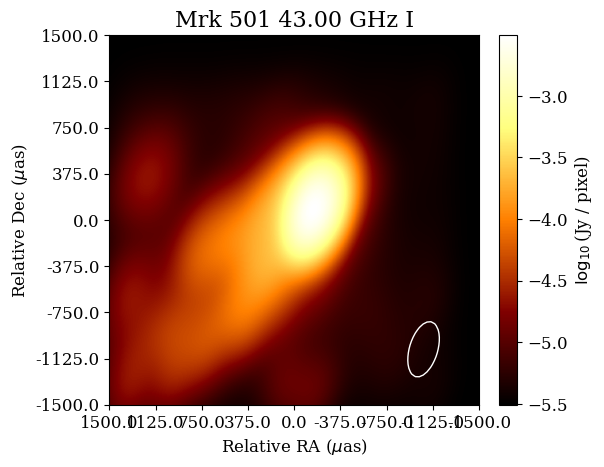

使用したビーム: 463.01293585963316 228.79748497018514 163.47657930099044
保存先: /Users/reiya/Desktop/imaging/results_fov3000/Mrk501_2023-07-01/blur_gauss


In [44]:
import ehtim as eh
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

####################################################
# 入出力の設定
####################################################
image_fits = Path(
    "/Users/reiya/Desktop/imaging/results_fov3000/"
    "Mrk501_2023-07-01/fits/1652+398Q.2023-07-01_mimg.fits"
)

output_dir = Path(
    "/Users/reiya/Desktop/imaging/results_fov3000/"
    "Mrk501_2023-07-01/blur_gauss"
)

output_dir.mkdir(parents=True, exist_ok=True)

output_fits = output_dir / "posterior_mean_blurred.fits"
output_png  = output_dir / "posterior_mean_blurred.png"


####################################################
# Comrade画像のFITSを読み込む
####################################################
im = eh.image.load_fits(str(image_fits))
im.source = "Mrk 501"
im.rf = 43.0e9

####################################################
# CLEAN画像と同じビームを指定
####################################################
# 以下の3つをCLEAN画像のビーム値に変更する
#major_uas = 344.12     # ビーム長軸 FWHM [μas]
#minor_uas = 228.80     # ビーム短軸 FWHM [μas]
#pa_deg    = 163.48     # ビーム位置角 [degree]

beamparams = [
    major_uas * eh.RADPERUAS,
    minor_uas * eh.RADPERUAS,
    np.deg2rad(pa_deg)
]


####################################################
# ガウシアンビームで畳み込み
####################################################
im_blur = im.blur_gauss(
    beamparams,
    frac=1.0 #✅
)


####################################################
# FITSで保存
####################################################
im_blur.save_fits(str(output_fits))


####################################################
# PNGで保存
####################################################
fig = im_blur.display(
    scale="log",
    dynamic_range=1000,
    beamparams=beamparams,
    show=False
)

fig.savefig(
    str(output_png),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("使用したビーム:", major_uas, minor_uas, pa_deg)
print("保存先:", output_dir)